# Residual-Based Drift Detector Evaluation & Benchmark Comparison om Milti Series

In [1]:
# Import required libraries
import sys
import os
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Add parent directory to path
sys.path.append(os.path.abspath(os.path.join('..')))

# Import project custom modules
from src.detector.data_loader import DataLoader
from src.detector.drift_generator import DriftGenerator
from src.detector.baseline_detectors import BaselineDetectorWrapper
from src.detector.residual_detector import ResidualConformalDriftDetector
from src.detector.generate_benchmarks import generate_multi_series_benchmarks
from src.detector.run_baseline_evaluation import run_all_baseline_detectors
from src.detector.run_residual_detector_evaluation import evaluate_residual_detector

# Styling setup
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

## Input data

In [2]:
data_dir = "../data"
processed_dir = Path(data_dir) / "processed"
manifest_path = processed_dir / "multi_series_benchmark_manifest.json"
baseline_results_path = processed_dir / "multi_series_baseline_evaluation_results.csv"

tcpd_list_of_datasets = ["jfk_passengers", "iceland_tourism", "us_population"]

tcpd_frequency_mapping = {
    "jfk_passengers": "MS",
    "lga_passengers": "MS",
    "construction": "MS",
    "iceland_tourism": "MS",
    "seatbelts": "MS",
    "us_population": "MS",
    "occupancy": "1min",
    "measles": "W"
}

tcpd_annotator_key_mapping = {
    "jfk_passengers": "10",
    "lga_passengers": "6",
    "construction": "8",
    "iceland_tourism": "12",
    "seatbelts": "8",
    "us_population": "9",
    "occupancy": "6",
    "measles": "12"
}

## 1. Data Reading

In [3]:
# Initialize data loader
loader = DataLoader(data_dir="../data")

# Load multi-series dictionaries
datasets = {
    "Alibaba": loader.load_alibaba_batch(n_series=2, seed=42),
    "UCI_Electricity": loader.load_uci_batch(n_series=5, resample_freq="1h", seed=42, check_window= ("2013-01-01", "2013-12-31")),
    "TCPD": loader.load_tcpd_batch(series_names=tcpd_list_of_datasets, frequency=tcpd_frequency_mapping, annotator_key=tcpd_annotator_key_mapping),
    # "SeisBench Iquique": loader.load_seisbench_iquique_batch(n_series=10, seed=42),
}

# Quick inspection loop to verify structure
for ds_name, series_dict in datasets.items():
    print(f"Dataset: {ds_name} | Loaded {len(series_dict)} time series.")
    for series_id, payload in list(series_dict.items())[:10]: # Preview first 10
        df, period = payload[0], payload[1]
        print(f"  -> Series ID: {series_id} | Shape: {df.shape} | Seasonal Period: {period}")

Dataset: Alibaba | Loaded 2 time series.
  -> Series ID: alibaba_mem_util_percent | Shape: (2243, 2) | Seasonal Period: 288
  -> Series ID: alibaba_net_in | Shape: (2243, 2) | Seasonal Period: 288
Dataset: UCI_Electricity | Loaded 5 time series.
  -> Series ID: MT_242 | Shape: (8760, 2) | Seasonal Period: 24
  -> Series ID: MT_241 | Shape: (8760, 2) | Seasonal Period: 24
  -> Series ID: MT_291 | Shape: (8760, 2) | Seasonal Period: 24
  -> Series ID: MT_209 | Shape: (8760, 2) | Seasonal Period: 24
  -> Series ID: MT_265 | Shape: (8760, 2) | Seasonal Period: 24
Dataset: TCPD | Loaded 3 time series.
  -> Series ID: jfk_passengers | Shape: (468, 2) | Seasonal Period: 12
  -> Series ID: iceland_tourism | Shape: (199, 2) | Seasonal Period: 12
  -> Series ID: us_population | Shape: (816, 2) | Seasonal Period: 12


## 2. Drift Benchmark Generation

In [4]:
generate_multi_series_benchmarks(datasets, data_dir="../data")

=== Starting 3-Level Multi-Series Benchmark Generation ===

Processing dataset batch: 'Alibaba' (2 time series)
 -> Processing series ID: alibaba_mem_util_percent
    [Level 1] Saved clean baseline -> level1_clean_Alibaba_alibaba_mem_util_percent.csv
    [Level 2] Completed drift injections for Alibaba-alibaba_mem_util_percent
 -> Processing series ID: alibaba_net_in
    [Level 1] Saved clean baseline -> level1_clean_Alibaba_alibaba_net_in.csv
    [Level 2] Completed drift injections for Alibaba-alibaba_net_in

Processing dataset batch: 'UCI_Electricity' (5 time series)
 -> Processing series ID: MT_242
    [Level 1] Saved clean baseline -> level1_clean_UCI_Electricity_MT_242.csv
    [Level 2] Completed drift injections for UCI_Electricity-MT_242
 -> Processing series ID: MT_241
    [Level 1] Saved clean baseline -> level1_clean_UCI_Electricity_MT_241.csv
    [Level 2] Completed drift injections for UCI_Electricity-MT_241
 -> Processing series ID: MT_291
    [Level 1] Saved clean baseli

## 3. Baseline Detector Evaluation

In [28]:
baseline_evaluation_df = run_all_baseline_detectors(data_dir="../data", manifest_file="multi_series_benchmark_manifest.json", output_file="multi_series_baseline_evaluation_results.csv")

=== Starting Baseline Detector Evaluation (3-Level Benchmark) ===
[Level 1 FAR] ks on Alibaba: 22.29 alarms/1000 pts
[Level 1 FAR] psi on Alibaba: 36.11 alarms/1000 pts
[Level 1 FAR] wasserstein on Alibaba: 31.65 alarms/1000 pts
[Level 1 FAR] adwin on Alibaba: 4.90 alarms/1000 pts
[Level 1 FAR] page_hinkley on Alibaba: 15.16 alarms/1000 pts
[Level 1 FAR] kswin on Alibaba: 8.92 alarms/1000 pts
[Level 1 FAR] ks on Alibaba: 34.77 alarms/1000 pts
[Level 1 FAR] psi on Alibaba: 36.56 alarms/1000 pts
[Level 1 FAR] wasserstein on Alibaba: 0.00 alarms/1000 pts
[Level 1 FAR] adwin on Alibaba: 2.67 alarms/1000 pts
[Level 1 FAR] page_hinkley on Alibaba: 0.89 alarms/1000 pts
[Level 1 FAR] kswin on Alibaba: 9.81 alarms/1000 pts
[Level 1 FAR] ks on UCI_Electricity: 3.65 alarms/1000 pts
[Level 1 FAR] psi on UCI_Electricity: 35.84 alarms/1000 pts
[Level 1 FAR] wasserstein on UCI_Electricity: 39.16 alarms/1000 pts
[Level 1 FAR] adwin on UCI_Electricity: 0.23 alarms/1000 pts
[Level 1 FAR] page_hinkley on

## 4. ResidualConformalDriftDetector on Benchmarks

In [6]:
with open(manifest_path, "r") as f:
    benchmark_manifest = json.load(f)

print(f"Total benchmark scenarios in manifest: {len(benchmark_manifest)}")

Total benchmark scenarios in manifest: 97


In [7]:
# Execute evaluation
df_residual = evaluate_residual_detector(benchmark_manifest, processed_dir)
display(df_residual.head())

,dataset,series_id,seasonality_strength,seasonality_group,level,drift_type,magnitude,method,false_alarms,far_per_1000,precision,recall,f1_score,detection_delay,detected
0,Alibaba,alibaba_mem_util_percent,0.5055,moderate,1,none,0.0,residual_conformal,30,13.374944,0.000000,0.0,0.000000,NaN,0.0
1,Alibaba,alibaba_mem_util_percent,0.5055,moderate,2,abrupt,0.5,residual_conformal,27,NaN,0.035714,1.0,0.068966,32.0,1.0
2,Alibaba,alibaba_mem_util_percent,0.5055,moderate,2,abrupt,1.0,residual_conformal,26,NaN,0.037037,1.0,0.071429,32.0,1.0
3,Alibaba,alibaba_mem_util_percent,0.5055,moderate,2,abrupt,2.0,residual_conformal,27,NaN,0.035714,1.0,0.068966,32.0,1.0
4,Alibaba,alibaba_mem_util_percent,0.5055,moderate,2,abrupt,3.0,residual_conformal,24,NaN,0.040000,1.0,0.076923,37.0,1.0


## 5. Combine Multi series Results & Compare with Classic Methods

In [29]:
df_baseline = pd.read_csv(baseline_results_path)
print(f"Loaded baseline results shape: {df_baseline.shape}")
display(df_baseline.head())

Loaded baseline results shape: (582, 15)


,dataset,series_id,seasonality_strength,seasonality_group,level,drift_type,magnitude,method,false_alarms,far_per_1000,precision,recall,f1_score,detection_delay,detected
0,Alibaba,alibaba_mem_util_percent,0.5055,moderate,1,none,0.0,ks,50.0,22.29,0.0,0.0,0.0,NaN,NaN
1,Alibaba,alibaba_mem_util_percent,0.5055,moderate,1,none,0.0,psi,81.0,36.11,0.0,0.0,0.0,NaN,NaN
2,Alibaba,alibaba_mem_util_percent,0.5055,moderate,1,none,0.0,wasserstein,71.0,31.65,0.0,0.0,0.0,NaN,NaN
3,Alibaba,alibaba_mem_util_percent,0.5055,moderate,1,none,0.0,adwin,11.0,4.90,0.0,0.0,0.0,NaN,NaN
4,Alibaba,alibaba_mem_util_percent,0.5055,moderate,1,none,0.0,page_hinkley,34.0,15.16,0.0,0.0,0.0,NaN,NaN


In [30]:
# Combine baseline and residual conformal detector results
df_comparison = pd.concat([df_baseline, df_residual], ignore_index=True)

# Save combined comparison results
df_comparison.to_csv(processed_dir / "multi_series_detector_comparison_results.csv", index=False)

df_comparison_level_1 = df_comparison[df_comparison['level'] == 1][["dataset", "level", "drift_type", "method", "false_alarms", "far_per_1000"]]
df_comparison_level_2 = df_comparison[df_comparison['level'] == 2][["dataset", "level", "drift_type", "magnitude", "method", "precision", "recall", "f1_score", "detection_delay", "detected"]]
df_comparison_level_3 = df_comparison[(df_comparison['level'] == 3) & (~df_comparison['dataset'].isin(["seismic_iquique_trace"]))][["dataset", "level", "drift_type", "method", "precision", "recall", "f1_score", "detection_delay", "detected"]]

## 6. Comparative Visualization

### 6.1 Level 1 Analysis: False Alarm Rate (FAR)

In [31]:
print("=== Level 1: Drift-Free False Alarm Summary ===")
summary_level_1 = df_comparison_level_1.groupby("method")[["false_alarms", "far_per_1000"]].mean().reset_index()
display(summary_level_1)

=== Level 1: Drift-Free False Alarm Summary ===


,method,false_alarms,far_per_1000
0,adwin,2.6,0.97100
1,ks,24.4,7.03000
2,kswin,16.3,3.96700
3,page_hinkley,154.4,27.79900
4,psi,175.1,29.97400
5,residual_conformal,29.2,6.04815
6,wasserstein,182.2,28.15900


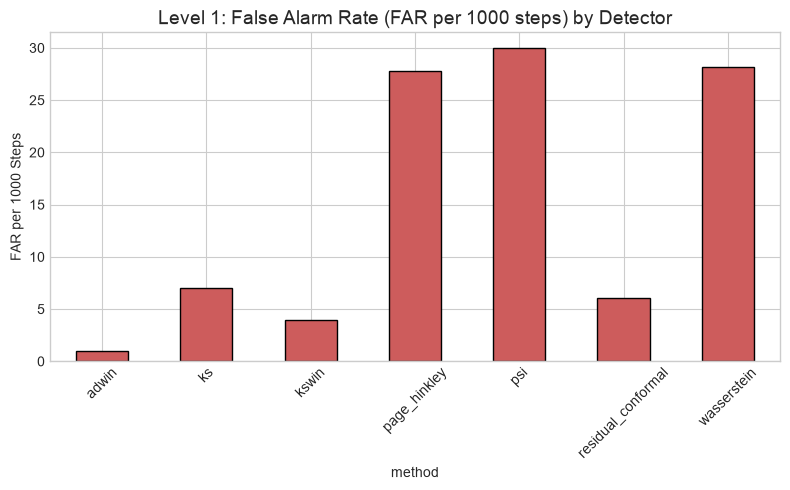

In [32]:
# Level 1 Plot: False Alarms by Detector
fig, ax = plt.subplots(figsize=(8, 5))
summary_level_1.set_index("method")["far_per_1000"].plot(kind="bar", ax=ax, color="indianred", edgecolor="black")
ax.set_title("Level 1: False Alarm Rate (FAR per 1000 steps) by Detector", fontsize=14)
ax.set_ylabel("FAR per 1000 Steps")
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### 6.2 Level 2 & 3 Analysis: Detection Performance

#### Level 2 Analysis

In [33]:
print("\n=== Level 2: Detection Performance Summary ===")
summary_levels_2 = df_comparison_level_2.groupby("method")[["f1_score", "precision", "recall", "detection_delay"]].mean().reset_index()
display(summary_levels_2)


=== Level 2: Detection Performance Summary ===


,method,f1_score,precision,recall,detection_delay
0,adwin,0.018690,0.010714,0.071429,693.000000
1,ks,0.024643,0.013690,0.416667,56.500000
2,kswin,0.028810,0.015357,0.261905,77.952381
3,page_hinkley,0.021071,0.014881,0.821429,28.869048
4,psi,0.021190,0.015476,0.976190,16.023810
5,residual_conformal,0.031866,0.016371,0.642857,20.796296
6,wasserstein,0.020714,0.014286,0.928571,21.380952


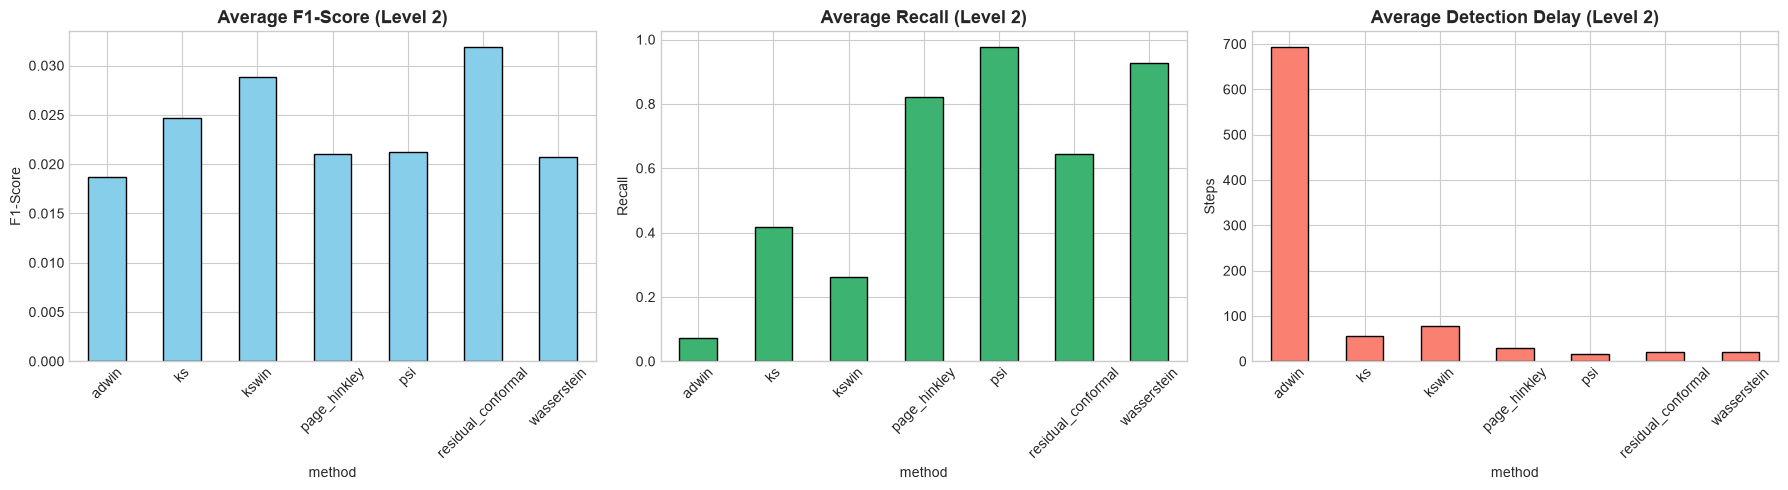

In [34]:
# Level 2 Plot: F1-Score, Recall, and Detection Delay
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. F1-Score Comparison
summary_levels_2.set_index("method")["f1_score"].plot(kind="bar", ax=axes[0], color="skyblue", edgecolor="black")
axes[0].set_title("Average F1-Score (Level 2)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("F1-Score")
axes[0].tick_params(axis='x', rotation=45)

# 2. Recall Comparison
summary_levels_2.set_index("method")["recall"].plot(kind="bar", ax=axes[1], color="mediumseagreen", edgecolor="black")
axes[1].set_title("Average Recall (Level 2)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Recall")
axes[1].tick_params(axis='x', rotation=45)

# 3. Detection Delay Comparison
summary_levels_2.set_index("method")["detection_delay"].plot(kind="bar", ax=axes[2], color="salmon", edgecolor="black")
axes[2].set_title("Average Detection Delay (Level 2)", fontsize=13, fontweight="bold")
axes[2].set_ylabel("Steps")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#### Level 3 Analysis

In [25]:
print("\n=== Level 3: Detection Performance Summary ===")
summary_levels_3 = df_comparison_level_3.groupby("method")[["f1_score", "precision", "recall", "detection_delay"]].mean().reset_index()
display(summary_levels_3)


=== Level 3: Detection Performance Summary ===


,method,f1_score,precision,recall,detection_delay
0,adwin,0.250000,0.180000,0.666667,20.500000
1,ks,0.100000,0.053333,0.666667,8.500000
2,kswin,0.073333,0.040000,0.333333,37.000000
3,page_hinkley,0.160000,0.093333,1.000000,10.666667
4,psi,0.083333,0.043333,0.666667,8.500000
5,residual_conformal,0.688889,0.583333,1.000000,10.666667
6,wasserstein,0.083333,0.043333,0.666667,8.500000


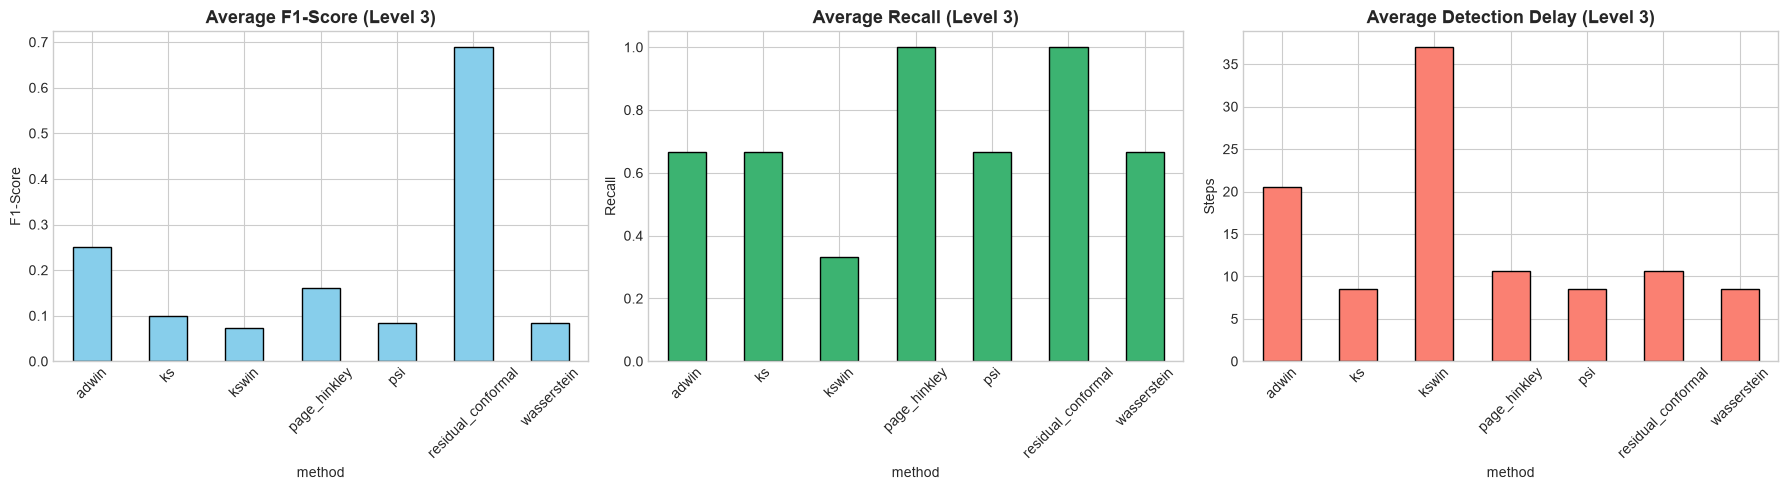

In [26]:
# Level 3 Plot: F1-Score, Recall, and Detection Delay
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. F1-Score Comparison
summary_levels_3.set_index("method")["f1_score"].plot(kind="bar", ax=axes[0], color="skyblue", edgecolor="black")
axes[0].set_title("Average F1-Score (Level 3)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("F1-Score")
axes[0].tick_params(axis='x', rotation=45)

# 2. Recall Comparison
summary_levels_3.set_index("method")["recall"].plot(kind="bar", ax=axes[1], color="mediumseagreen", edgecolor="black")
axes[1].set_title("Average Recall (Level 3)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Recall")
axes[1].tick_params(axis='x', rotation=45)

# 3. Detection Delay Comparison
summary_levels_3.set_index("method")["detection_delay"].plot(kind="bar", ax=axes[2], color="salmon", edgecolor="black")
axes[2].set_title("Average Detection Delay (Level 3)", fontsize=13, fontweight="bold")
axes[2].set_ylabel("Steps")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#### Level 2 & 3 Combined Analysis

In [27]:
# Combine Level 2 and 3 for overall detection capability evaluation
df_comparison_levels_2_3 = pd.concat([df_comparison_level_2, df_comparison_level_3])

print("\n=== Level 2 & 3: Detection Performance Summary ===")
summary_levels_2_3 = df_comparison_levels_2_3.groupby("method")[["f1_score", "precision", "recall", "detection_delay"]].mean().reset_index()
display(summary_levels_2_3)


=== Level 2 & 3: Detection Performance Summary ===


,method,f1_score,precision,recall,detection_delay
0,adwin,0.026667,0.016552,0.091954,677.360465
1,ks,0.027241,0.015057,0.425287,55.383721
2,kswin,0.037471,0.019885,0.333333,84.129412
3,page_hinkley,0.025862,0.017586,0.827586,28.241379
4,psi,0.023333,0.016437,0.965517,15.848837
5,residual_conformal,0.054522,0.035921,0.655172,20.263158
6,wasserstein,0.022874,0.015287,0.919540,21.081395


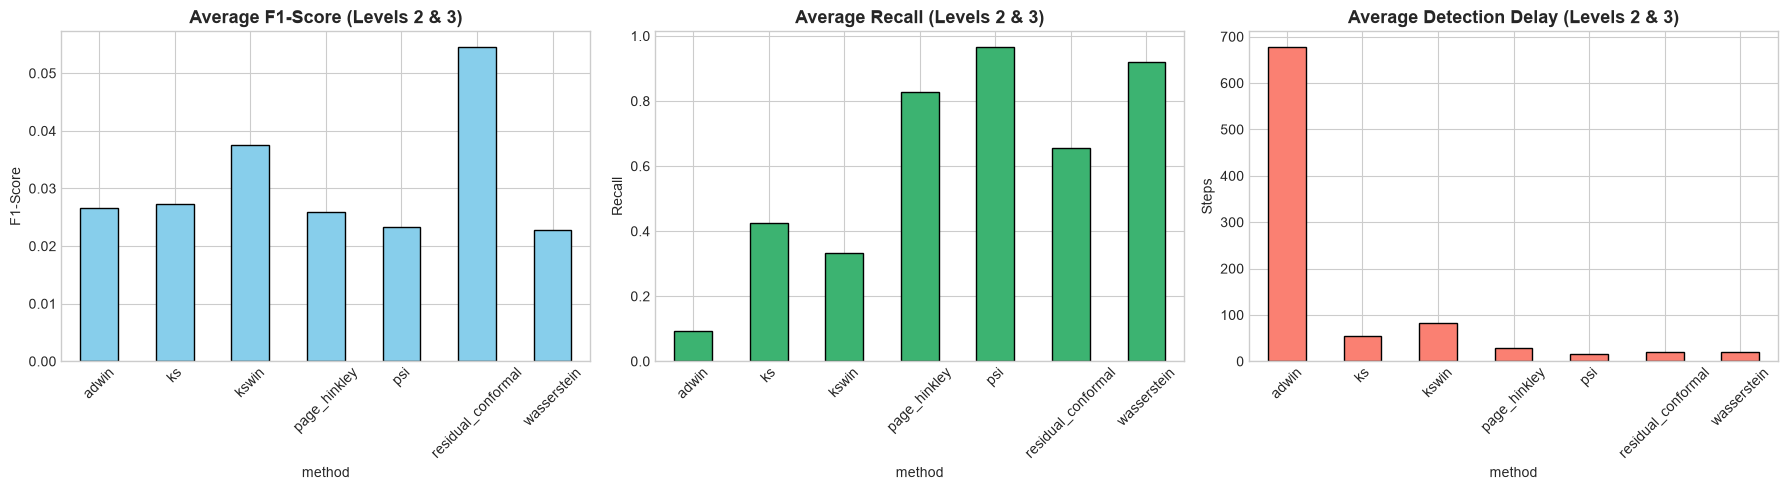

In [17]:
# Level 2 & 3 Plots: F1-Score, Recall, and Detection Delay
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. F1-Score Comparison
summary_levels_2_3.set_index("method")["f1_score"].plot(kind="bar", ax=axes[0], color="skyblue", edgecolor="black")
axes[0].set_title("Average F1-Score (Levels 2 & 3)", fontsize=13, fontweight="bold")
axes[0].set_ylabel("F1-Score")
axes[0].tick_params(axis='x', rotation=45)

# 2. Recall Comparison
summary_levels_2_3.set_index("method")["recall"].plot(kind="bar", ax=axes[1], color="mediumseagreen", edgecolor="black")
axes[1].set_title("Average Recall (Levels 2 & 3)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Recall")
axes[1].tick_params(axis='x', rotation=45)

# 3. Detection Delay Comparison
summary_levels_2_3.set_index("method")["detection_delay"].plot(kind="bar", ax=axes[2], color="salmon", edgecolor="black")
axes[2].set_title("Average Detection Delay (Levels 2 & 3)", fontsize=13, fontweight="bold")
axes[2].set_ylabel("Steps")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### 6.3 Performance Comparison by Seasonality Group

#### Level 1 False Alarm Rate (FAR) by Seasonality Group

=== Level 1: Average FAR per 1000 Steps by Seasonality Group ===


method,adwin,ks,kswin,page_hinkley,psi,residual_conformal,wasserstein
seasonality_group,,,,,,,
weak,2.6700,34.770,9.8100,0.8900,36.56000,12.929113,0.0000
moderate,4.9000,22.290,8.9200,15.1600,36.11000,13.374944,31.6500
strong,0.2675,1.655,2.6175,32.7425,28.38375,4.272181,31.2425


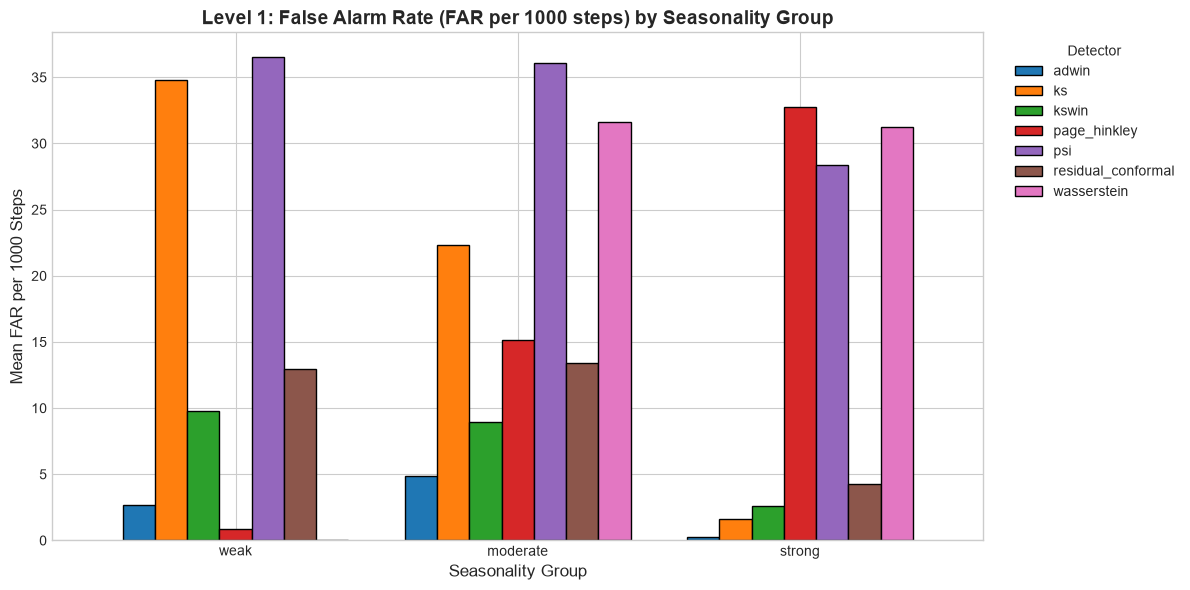

In [35]:
df_l1_season = df_comparison[df_comparison['level'] == 1].copy()

# Order seasonality groups logically if present
season_order = [g for g in ["weak", "moderate", "strong"] if g in df_l1_season["seasonality_group"].unique()]
if not season_order:
    season_order = sorted(df_l1_season["seasonality_group"].dropna().unique())

summary_l1_season = (
    df_l1_season.groupby(["seasonality_group", "method"])["far_per_1000"]
    .mean()
    .unstack("method")
    .reindex(season_order)
)

print("=== Level 1: Average FAR per 1000 Steps by Seasonality Group ===")
display(summary_l1_season)

# Plot Level 1 FAR by Seasonality Group
fig, ax = plt.subplots(figsize=(12, 6))
summary_l1_season.plot(kind="bar", ax=ax, edgecolor="black", width=0.8)

ax.set_title("Level 1: False Alarm Rate (FAR per 1000 steps) by Seasonality Group", fontsize=14, fontweight="bold")
ax.set_xlabel("Seasonality Group", fontsize=12)
ax.set_ylabel("Mean FAR per 1000 Steps", fontsize=12)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Detector", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

#### Level 2 & 3 Detection Performance (F1-Score, Recall, Delay) by Seasonality Group

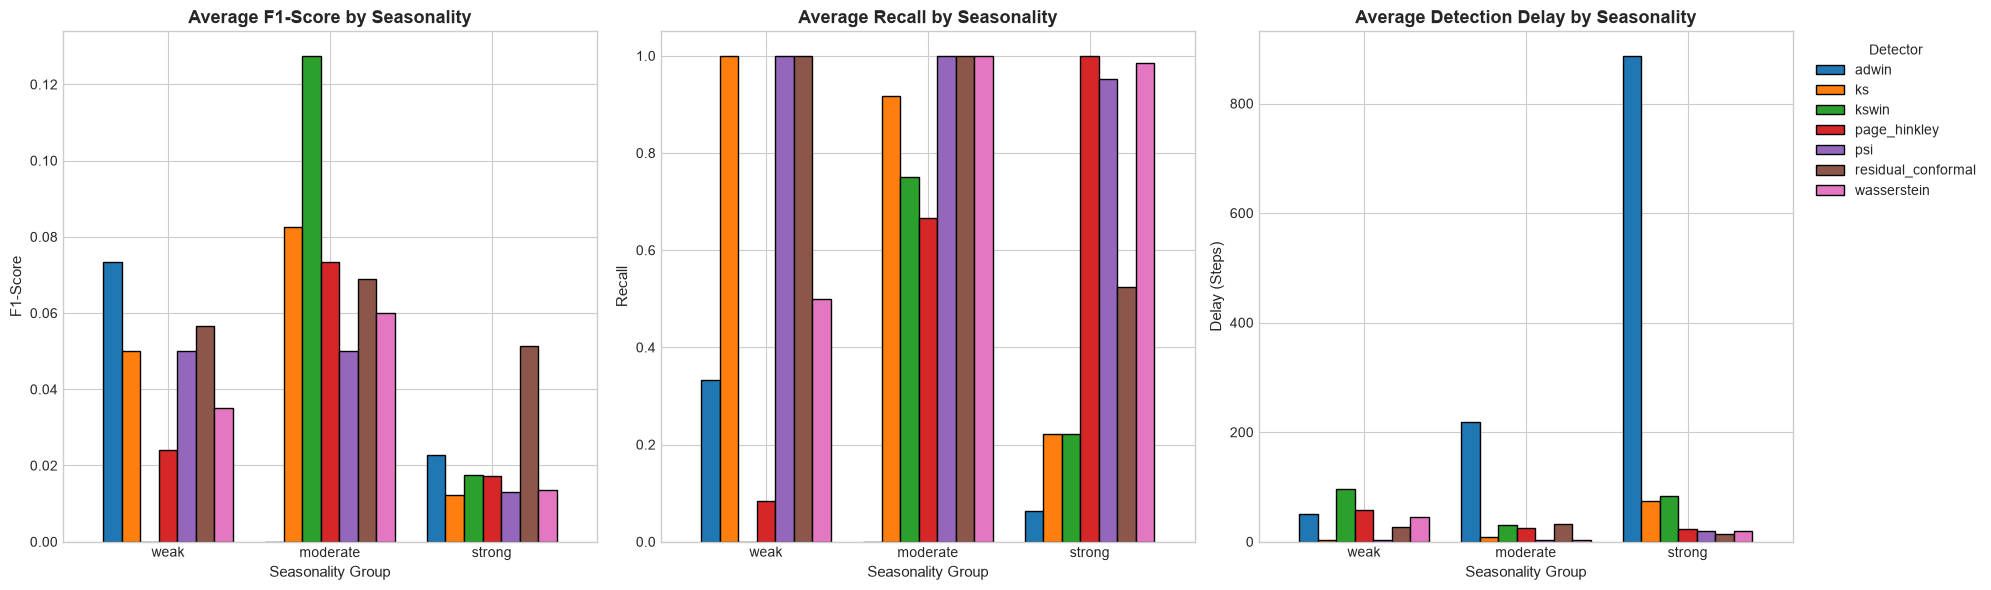

=== Levels 2 & 3: Detection Performance Summary by Seasonality Group ===


f1_score  precision    recall  \
seasonality_group method                                              
weak              adwin               0.073333   0.040000  0.333333   
                  ks                  0.050000   0.030000  1.000000   
                  kswin               0.000000   0.000000  0.000000   
                  page_hinkley        0.024167   0.014167  0.083333   
                  psi                 0.050000   0.030000  1.000000   
                  residual_conformal  0.056470   0.029059  1.000000   
                  wasserstein         0.035000   0.020000  0.500000   
moderate          adwin               0.000000   0.000000  0.000000   
                  ks                  0.082500   0.045833  0.916667   
                  kswin               0.127500   0.067500  0.750000   
                  page_hinkley        0.073333   0.040000  0.666667   
                  psi                 0.050000   0.030000  1.000000   
                  residual_conformal  0.068851   0.035658  1.000000   
                  wasserstein         0.060000   0.030000  1.000000   
strong            adwin               0.022857   0.015238  0.063492   
                  ks                  0.012381   0.006349  0.222222   
                  kswin               0.017619   0.009524  0.222222   
                  page_hinkley        0.017143   0.013968  1.000000   
                  psi                 0.013175   0.011270  0.952381   
                  residual_conformal  0.051422   0.037279  0.523810   
                  wasserstein         0.013492   0.011587  0.984127   

                                      detection_delay  
seasonality_group method                               
weak              adwin                     51.333333  
                  ks                         4.000000  
                  kswin                     95.500000  
                  page_hinkley              58.583333  
                  psi                        4.000000  
                  residual_conformal        27.083333  
                  wasserstein               45.666667  
moderate          adwin                    219.333333  
                  ks                         8.166667  
                  kswin                     30.750000  
                  page_hinkley              25.500000  
                  psi                        4.000000  
                  residual_conformal        32.416667  
                  wasserstein                4.000000  
strong            adwin                    887.177419  
                  ks                        74.467742  
                  kswin                     83.114754  
                  page_hinkley              22.984127  
                  psi                       20.435484  
                  residual_conformal        13.363636  
                  wasserstein               19.629032

In [38]:
df_drift_season = df_comparison[
    (df_comparison['level'].isin([2, 3])) & 
    (~df_comparison['dataset'].isin(["seismic_iquique_trace"]))
].copy()

metrics = ["f1_score", "recall", "detection_delay"]
titles = ["Average F1-Score by Seasonality", "Average Recall by Seasonality", "Average Detection Delay by Seasonality"]
ylabels = ["F1-Score", "Recall", "Delay (Steps)"]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for idx, (metric, title, ylabel) in enumerate(zip(metrics, titles, ylabels)):
    pivot_df = (
        df_drift_season.groupby(["seasonality_group", "method"])[metric]
        .mean()
        .unstack("method")
        .reindex(season_order)
    )
    
    pivot_df.plot(kind="bar", ax=axes[idx], edgecolor="black", width=0.8, legend=(idx == 2))
    axes[idx].set_title(title, fontsize=13, fontweight="bold")
    axes[idx].set_xlabel("Seasonality Group", fontsize=11)
    axes[idx].set_ylabel(ylabel, fontsize=11)
    axes[idx].tick_params(axis="x", rotation=0)

# Place a single shared legend to the right of the last subplot
axes[2].legend(title="Detector", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

# Display combined summary table across all metrics by Seasonality Group
summary_drift_season = (
    df_drift_season.groupby(["seasonality_group", "method"])[["f1_score", "precision", "recall", "detection_delay"]]
    .mean()
    .reindex(season_order, level=0)
)
print("=== Levels 2 & 3: Detection Performance Summary by Seasonality Group ===")
display(summary_drift_season)